# Day 1 — Data and Mathematical Foundation

## Goal

Understand how customer data becomes mathematical input for Logistic Regression.

## Core Idea

X = input features

y = target

For one customer:

X = [x₁, x₂, ..., xₙ]

The linear model calculates:

z = wᵀX + b

Where:

- X = feature vector
- w = weight vector
- b = bias
- z = linear combination

In [43]:
import pandas as pd

df = pd.read_csv("../data/dataset.csv")

df.head()

,age,tenure,monthly_charges,support_calls,contract_type,churn
0,22,2,75,5,month-to-month,1
1,45,36,55,1,two-year,0
2,31,8,90,4,month-to-month,1
3,52,48,60,1,two-year,0
4,28,5,85,3,month-to-month,1


In [44]:


X = df.drop("churn", axis=1)
y = df["churn"]

print("Features (X):")
print(X)

print("\nTarget (y):")
print(y)

Features (X):
    age  tenure  monthly_charges  support_calls   contract_type
0    22       2               75              5  month-to-month
1    45      36               55              1        two-year
2    31       8               90              4  month-to-month
3    52      48               60              1        two-year
4    28       5               85              3  month-to-month
5    39      24               65              2        one-year
6    61      60               50              0        two-year
7    25       4               95              6  month-to-month
8    47      30               58              1        one-year
9    34      12               88              4  month-to-month
10   56      42               62              1        two-year
11   29       7               78              5  month-to-month
12   41      18               70              2        one-year
13   63      55               52              0        two-year
14   36      10           

In [45]:
x = [22, 2, 75, 5]
w = [0.1, 0.2, 0.05, 0.3]
b = 1

z = (
    w[0] * x[0]
    + w[1] * x[1]
    + w[2] * x[2]
    + w[3] * x[3]
    + b
)

print("z =", z)

z = 8.85


In [46]:
import numpy as np

x = np.array([22, 2, 75, 5])
w = np.array([0.1, 0.2, 0.05, 0.3])
b = 1

z = np.dot(w, x) + b

print("wᵀx + b =", z)

wᵀx + b = 8.85


## Linear Model

For one customer, our numerical feature vector is:

x = [x₁, x₂, ..., xₙ]

The model has a weight vector:

w = [w₁, w₂, ..., wₙ]

The linear model calculates:

z = wᵀx + b

The dot product is:

wᵀx = w₁x₁ + w₂x₂ + ... + wₙxₙ

For our example:

x = [22, 2, 75, 5]

w = [0.1, 0.2, 0.05, 0.3]

b = 1

Therefore:

z = (0.1×22) + (0.2×2) + (0.05×75) + (0.3×5) + 1

z = 8.85

### Important

The model has not learned these weights yet.

We selected them manually only to understand the mathematics.

Later, gradient descent will learn the weights from the data.

## Numerical vs Categorical Features

Our dataset contains two types of features.

### Numerical features

These already have numerical values:

- age
- tenure
- monthly_charges
- support_calls

Example:

x = [22, 2, 75, 5]

These can directly participate in mathematical operations.

### Categorical feature

contract_type contains categories:

- month-to-month
- one-year
- two-year

These cannot directly be multiplied by numerical weights.

Therefore, we will transform the categorical feature into a numerical representation.

We will learn and implement this encoding during Day 2.

### Important

We should not simply assign:

month-to-month = 1
one-year = 2
two-year = 3

without understanding the consequences, because those numbers could incorrectly suggest an ordered relationship.


## Dimensions of X and w

Our dataset contains:

- 20 customers
- 4 numerical features used for today's mathematical example

Therefore:

X ∈ R^(20×4)

For one customer:

x ∈ R^4

The weight vector contains one weight for every feature:

w ∈ R^4

Therefore the dot product is valid:

wᵀx

because both x and w contain 4 corresponding values.

The linear model is:

z = wᵀx + b

The model has one weight for each input feature.

In [47]:
print("X shape:", X.shape)

x_numeric = X[["age", "tenure", "monthly_charges", "support_calls"]].iloc[0].to_numpy()

print("One customer x:", x_numeric)
print("Number of features:", len(x_numeric))

X shape: (20, 5)
One customer x: [22  2 75  5]
Number of features: 4


In [48]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import load_data

dataset_path = PROJECT_ROOT / "data" / "dataset.csv"

df_test = load_data(dataset_path)

print("Shape:", df_test.shape)
print(df_test.head())

Shape: (20, 6)
   age  tenure  monthly_charges  support_calls   contract_type  churn
0   22       2               75              5  month-to-month      1
1   45      36               55              1        two-year      0
2   31       8               90              4  month-to-month      1
3   52      48               60              1        two-year      0
4   28       5               85              3  month-to-month      1


# Day 2 — Preprocessing and Logistic Regression Mathematics


## Goal

Transform raw dataset features into standardized numerical inputs, then apply the Sigmoid function to output probabilities.


## Core Idea

Machine learning models only understand numbers, and they learn best when those numbers are on a similar scale.

->Train/Test Split: Isolate a test set to evaluate real-world performance later.

->Encoding: Convert text categories (like "month-to-month") into 0s and 1s.

->Standardization: x−μ/σ

->Sigmoid: σ(z)= 1/1+e^(−z)

In [49]:
import numpy as np
import pandas as pd
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

# Import the functions you wrote!
from src.preprocessing import (
    load_data, train_test_split, encode_categorical, 
    calculate_mean, calculate_std, standardize
)
from src.logistic_regression import (
    sigmoid, predict_probability, probability_to_class
)

dataset_path = PROJECT_ROOT / "data" / "dataset.csv"
df = load_data(dataset_path)

X = df.drop("churn", axis=1)
y = df["churn"]

## 1. Train / Test Split

If a student sees the exam paper before the test, getting a 100% doesn't mean they are smart—it just means they memorized it! The same applies to Machine Learning. We must hide some data (the test set) so we can evaluate the model fairly later.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (16, 5)
Testing features shape: (4, 5)


## 2. Categorical Encoding (One-Hot Encoding)
In Day 1, we saw that contract_type contains text like "month-to-month" or "two-year". You cannot multiply a weight w 
i
​	
  by "month-to-month"!

We could just assign 1, 2, and 3 to them. But the model would think that "two-year" (3) is mathematically greater or worth more than "month-to-month" (1). Instead, we use your encode_categorical function to create binary flags.

In [51]:
X_train_encoded, X_test_encoded = encode_categorical(X_train, X_test)

print("Original Data (First 2 rows):")
print(X_train[["age", "contract_type"]].head(2))

print("\nEncoded Data (First 2 rows):")
print(X_train_encoded[["age", "month-to-month", "one-year", "two-year"]].head(2))

Original Data (First 2 rows):
    age contract_type
12   41      one-year
10   56      two-year

Encoded Data (First 2 rows):
    age  month-to-month  one-year  two-year
12   41               0         1         0
10   56               0         0         1


## 3. Feature Standardization
Right now, age might be around 40, but monthly_charges might be 90. If we do not scale these, the gradients for larger features will bounce around wildly during gradient descent.

We standardize them using the training mean μ and standard deviation σ:

x(scaled) = x−μ / σ
​	

Important: We must calculate the mean and standard deviation strictly on the training set, and use those exact same values to scale the test set!

In [52]:
# Convert to NumPy for mathematical operations
X_train_num = X_train_encoded.to_numpy(dtype=float)
X_test_num = X_test_encoded.to_numpy(dtype=float)
y_train_num = y_train.to_numpy(dtype=int)

# Calculate mu and sigma on training data
train_mean = calculate_mean(X_train_num)
train_std = calculate_std(X_train_num, train_mean)

# Scale both sets
X_train_scaled = standardize(X_train_num, train_mean, train_std)
X_test_scaled = standardize(X_test_num, train_mean, train_std)

print("First customer BEFORE scaling:")
print(np.round(X_train_num[0], 2))

print("\nFirst customer AFTER scaling:")
print(np.round(X_train_scaled[0], 2))

First customer BEFORE scaling:
[41. 18. 70.  2.  0.  1.  0.]

First customer AFTER scaling:
[-0.1  -0.47  0.08 -0.17 -0.77  1.73 -0.77]


## 4. The Sigmoid Function

We use the Sigmoid function, which smoothly squishes any number between −∞ and +∞ into a range between 0 and 1:

In [53]:
sample_z = np.array([-5, 0, 8.85])
print("z values:", sample_z)
print("Probabilities:", np.round(sigmoid(sample_z), 4))

z values: [-5.    0.    8.85]
Probabilities: [0.0067 0.5    0.9999]


## 5. Putting it all together: Making Predictions

Now, let's use all your functions together. We will set up some dummy weights (since we haven't learned Gradient Descent yet), calculate the probabilities, and use probability_to_class function to make the final decision!

In [54]:
# We now have 7 features (age, tenure, charges, calls, and 3 contract types)
w_dummy = np.array([0.1, -0.4, 0.2, 0.5, 0.3, -0.2, -0.5])
b_dummy = 0.0

# 1. Calculate probabilities for the first 5 training customers
probs = predict_probability(X_train_scaled[:5], w_dummy, b_dummy)

# 2. Convert probabilities to final class predictions (threshold = 0.5)
predictions = probability_to_class(probs, threshold=0.5)

print("Customer | Probability | Prediction | Actual")
print("-" * 46)
for i in range(5):
    p = probs[i]
    pred = predictions[i]
    actual = y_train_num[i]
    print(f"   {i}     |    {p:.4f}   |      {pred}     |   {actual}")

Customer | Probability | Prediction | Actual
----------------------------------------------
   0     |    0.4789   |      0     |   0
   1     |    0.1927   |      0     |   0
   2     |    0.0980   |      0     |   0
   3     |    0.1547   |      0     |   0
   4     |    0.1655   |      0     |   0


# Day 3 — Model Training

## 1. What Does Training Mean?

In Day 2, we used manually selected dummy weights to make predictions.

Those weights were not learned from the dataset.

Training means finding weights and a bias that make the model's predictions increasingly better.

The basic training cycle is:

Initial weights
↓
Prediction
↓
Calculate loss
↓
Calculate gradients
↓
Update weights and bias
↓
Repeat

The Logistic Regression prediction is:

z = wᵀx + b

p = σ(z)

Day 3 will now explain how the model measures its prediction error and uses that error to learn better parameters.

## 2. Binary Cross-Entropy Loss

After the model makes a probability prediction, we need to measure how wrong that prediction is.

For binary classification, we use Binary Cross-Entropy (BCE), also called Log Loss.

For one example:

L = -[y log(p) + (1-y) log(1-p)]

Where:

- y = actual class (0 or 1)
- p = predicted probability
- L = loss

If y = 1:

L = -log(p)

If y = 0:

L = -log(1-p)

A correct and confident prediction gives a small loss.

A wrong and confident prediction gives a large loss.

The goal of training is to find weights and bias that minimize the loss.

## 3. Understanding Loss with Numbers

Let's calculate Binary Cross-Entropy loss for different predicted probabilities.

For this experiment, the actual class is:

y = 1

Therefore:

L = -log(p)

A prediction close to 1 should produce a small loss.

A prediction close to 0 should produce a large loss.

In [55]:
import numpy as np

y = 1

probabilities = np.array([0.99, 0.9, 0.7, 0.5, 0.1, 0.01])

losses = -(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities))

for p, loss in zip(probabilities, losses):
    print(f"Probability = {p:.2f} → Loss = {loss:.4f}")

Probability = 0.99 → Loss = 0.0101
Probability = 0.90 → Loss = 0.1054
Probability = 0.70 → Loss = 0.3567
Probability = 0.50 → Loss = 0.6931
Probability = 0.10 → Loss = 2.3026
Probability = 0.01 → Loss = 4.6052


### Actual Class = 0

Now suppose the customer did NOT churn:

y = 0

The BCE formula becomes:

L = -log(1-p)

Therefore, a prediction close to 0 should have a small loss, while a prediction close to 1 should have a large loss.

In [56]:
y = 0

probabilities = np.array([0.01, 0.1, 0.3, 0.5, 0.9, 0.99])

losses = -(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities))

for p, loss in zip(probabilities, losses):
    print(f"Probability = {p:.2f} → Loss = {loss:.4f}")

Probability = 0.01 → Loss = 0.0101
Probability = 0.10 → Loss = 0.1054
Probability = 0.30 → Loss = 0.3567
Probability = 0.50 → Loss = 0.6931
Probability = 0.90 → Loss = 2.3026
Probability = 0.99 → Loss = 4.6052


## 5. Derivative of the Sigmoid Function

The sigmoid function is:

σ(z) = 1 / (1 + e⁻ᶻ)

We need its derivative because our Logistic Regression model has the following chain:

w → z → p → L

where:

z = wᵀx + b

p = σ(z)

L = Binary Cross-Entropy Loss

Therefore, we need to know how p changes when z changes:

dp/dz

### Step 1 — Rewrite the sigmoid

σ(z) = (1 + e⁻ᶻ)⁻¹

Using the chain rule:

dσ/dz
= -(1 + e⁻ᶻ)⁻² × (-e⁻ᶻ)

Therefore:

dσ/dz = e⁻ᶻ / (1 + e⁻ᶻ)²

### Step 2 — Rewrite the derivative using the sigmoid itself

We have:

dσ/dz = e⁻ᶻ / (1 + e⁻ᶻ)²

Split the fraction:

dσ/dz
= [1 / (1 + e⁻ᶻ)] [e⁻ᶻ / (1 + e⁻ᶻ)]

The first term is the sigmoid:

1 / (1 + e⁻ᶻ) = σ(z)

For the second term:

e⁻ᶻ / (1 + e⁻ᶻ)

= [(1 + e⁻ᶻ) - 1] / (1 + e⁻ᶻ)

= 1 - 1/(1 + e⁻ᶻ)

= 1 - σ(z)

Therefore:

dσ/dz = σ(z)(1 - σ(z))

### Final Result

Therefore, the derivative of the sigmoid is:

dσ/dz = σ(z)(1 - σ(z))

If:

p = σ(z)

then we can write:

dp/dz = p(1-p)

### Why Does the Derivative Have This Form?

The derivative does NOT equal the sigmoid simply because we chose it that way.

We first differentiate:

σ(z) = 1/(1 + e⁻ᶻ)

The derivative is initially:

dσ/dz = e⁻ᶻ/(1 + e⁻ᶻ)²

Then algebraically rewrite it using the original sigmoid function.

This produces:

dσ/dz = σ(z)(1 - σ(z))

This is a special and useful property of the logistic sigmoid.

### Why Do We Need This in Logistic Regression?

Our model is:

z = wᵀx + b

Then:

p = σ(z)

Then:

L = -[y log(p) + (1-y)log(1-p)]

The dependency chain is:

w → z → p → L

Using the chain rule:

∂L/∂w
=
(∂L/∂p)
(∂p/∂z)
(∂z/∂w)

We now know:

∂p/∂z = p(1-p)

This will allow us to derive the complete Logistic Regression gradient.

### Important Mathematical Insight

The sigmoid derivative is largest around z = 0.

At z = 0:

σ(0) = 0.5

Therefore:

σ'(0) = 0.5(1 - 0.5)
      = 0.25

For very large positive or negative z:

σ'(z) → 0

Therefore, the sigmoid changes most rapidly around its center and becomes flatter toward its two extremes.

## 6. Gradient Descent

Gradient Descent is an iterative optimization algorithm used to find model parameters that minimize the loss.

Our Logistic Regression model calculates:

z = wᵀx + b

p = sigmoid(z)

Then we calculate the Binary Cross-Entropy loss.

The gradients are:

∂L/∂w = (p-y)x

∂L/∂b = p-y

Gradient Descent updates the parameters in the opposite direction of the gradient.

Weight update:

w := w - α(∂L/∂w)

Bias update:

b := b - α(∂L/∂b)

where α is the learning rate.

The learning rate controls the size of each parameter update.

A large learning rate makes large updates.
A small learning rate makes small updates.

The training process is repeated for multiple epochs.

One epoch means one complete pass through the training dataset.

Complete learning loop:

X
↓
z = wᵀx + b
↓
p = sigmoid(z)
↓
loss
↓
gradient
↓
update w and b
↓
repeat

The goal is to repeatedly update the parameters so that the loss decreases and eventually stabilizes.

## 7. Batch Gradient and Averaging

For one training example, we derived:

∂L/∂w = (p-y)x

∂L/∂b = p-y

However, our model is trained using multiple examples.

For m training examples, each example produces its own gradient.

The gradient of the total cost is the average of the individual gradients:

∂J/∂w = (1/m) Σᵢ (pᵢ-yᵢ)xᵢ

∂J/∂b = (1/m) Σᵢ (pᵢ-yᵢ)

where m is the number of training examples.

For ChurnLab:

m = 16

Therefore, during batch gradient descent:

16 training examples
↓
calculate predictions
↓
calculate individual errors
↓
calculate individual gradients
↓
average the gradients
↓
update weights and bias

This is called Batch Gradient Descent because the complete training batch is used to calculate the gradient before updating the parameters.

The important idea is:

One customer → one gradient

All customers → average gradient

Average gradient → one parameter update

## 8. Complete Logistic Regression Training Loop

We now combine all the mathematical concepts learned in Day 3.

### Step 1 — Initialize

Start with initial weights and bias.

For our 7 input features:

w = [w₁, w₂, ..., w₇]

b = 0

The model has not learned these parameters yet.

### Step 2 — Linear Prediction

Calculate the linear score:

z = Xw + b

### Step 3 — Probability

Apply the sigmoid function:

p = σ(z)

where:

σ(z) = 1 / (1 + e⁻ᶻ)

The result is a probability between 0 and 1.

### Step 4 — Calculate Binary Cross-Entropy Loss

J = -(1/m) Σ [yᵢ log(pᵢ) + (1-yᵢ)log(1-pᵢ)]

The loss measures how different our predictions are from the actual labels.

### Step 5 — Calculate Gradients

Weight gradient:

∇wJ = (1/m) Xᵀ(p-y)

Bias gradient:

∂J/∂b = (1/m) Σ(p-y)

The gradients tell us how the parameters should change to reduce the loss.

### Step 6 — Update Parameters

Using the learning rate α:

w := w - α∇wJ

b := b - α(∂J/∂b)

### Step 7 — Repeat

Repeat the complete process for multiple epochs.

Complete training loop:

Initialize w and b
↓
Calculate z
↓
Calculate probability p
↓
Calculate loss J
↓
Calculate gradients
↓
Update w and b
↓
Repeat for the next epoch

One complete pass through the training data is called an epoch.

The goal of training is to find values of w and b that produce a low loss.

### Complete Mathematical Pipeline

X
↓
z = Xw + b
↓
p = sigmoid(z)
↓
Binary Cross-Entropy Loss
↓
Gradients
↓
Gradient Descent
↓
Updated w and b
↓
Repeat

In [57]:
from src.logistic_regression import LogisticRegression
model = LogisticRegression()

y_true = np.array([1, 0, 1, 1])
probabilities = np.array([0.9, 0.2, 0.8, 0.7])

loss = model.binary_cross_entropy(y_true, probabilities)

print("Binary Cross-Entropy Loss:", loss)

Binary Cross-Entropy Loss: 0.22708064055624455


In [58]:
import importlib
import src.logistic_regression as lr

importlib.reload(lr)

from src.logistic_regression import LogisticRegression

In [59]:
print(hasattr(LogisticRegression, "calculate_gradients"))

True


In [60]:
X_sample = np.array([
    [1.0, 2.0],
    [2.0, 1.0],
    [3.0, 4.0]
])

y_sample = np.array([1, 0, 1])

probabilities_sample = np.array([0.8, 0.3, 0.9])

model = LogisticRegression()

weight_gradient, bias_gradient = model.calculate_gradients(
    X_sample,
    y_sample,
    probabilities_sample
)

print("Weight gradient:", weight_gradient)
print("Bias gradient:", bias_gradient)

Weight gradient: [ 0.03333333 -0.16666667]
Bias gradient: 1.850371707708594e-17


In [61]:
import numpy as np

from src.logistic_regression import LogisticRegression

In [62]:
import numpy as np
from src.logistic_regression import LogisticRegression

In [63]:
from pathlib import Path

path = Path("../src/logistic_regression.py")

print(path.read_text())

import numpy as np


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def predict_probability(X, w, b):
    z = np.dot(X, w) + b
    return sigmoid(z)


def probability_to_class(probabilities, threshold=0.5):
    # If probability is greater than or equal to the threshold,
    # predict class 1. Otherwise, predict class 0.
    return (probabilities >= threshold).astype(int)


class LogisticRegression:

    def __init__(self, learning_rate=0.01, epochs=1000):
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = 0
        self.loss_history = []

    def binary_cross_entropy(self, y_true, probabilities):
        epsilon = 1e-15

        probabilities = np.clip(probabilities, epsilon, 1 - epsilon) ##Keep every probability between epsilon and 1-epsilon

        loss = -np.mean(
            y_true * np.log(probabilities) + (1 - y_true) * np.log(1 - probabilities)
        )

        return loss

    def calculate_gradients(sel

In [64]:
model = lr.LogisticRegression(learning_rate=0.1)

print(hasattr(model, "update_parameters"))

True


In [65]:
model.weights = np.array([0.5, -0.5])
model.bias = 0.2

weight_gradient = np.array([0.1, -0.2])
bias_gradient = 0.05

print("Before update:")
print("Weights:", model.weights)
print("Bias:", model.bias)

model.update_parameters(weight_gradient, bias_gradient)

print("\nAfter update:")
print("Weights:", model.weights)
print("Bias:", model.bias)

Before update:
Weights: [ 0.5 -0.5]
Bias: 0.2

After update:
Weights: [ 0.49 -0.48]
Bias: 0.195


In [66]:
import importlib
import src.logistic_regression as lr

importlib.reload(lr)

print(lr.LogisticRegression.__dict__.keys())

dict_keys(['__module__', '__firstlineno__', '__init__', 'binary_cross_entropy', 'calculate_gradients', 'update_parameters', 'fit', '__static_attributes__', '__dict__', '__weakref__', '__doc__'])


In [67]:
model = lr.LogisticRegression(
    learning_rate=0.1,
    epochs=10
)

print(hasattr(model, "fit"))

True


In [68]:
X_sample = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_sample = np.array([0, 0, 0, 1])

model.fit(X_sample, y_sample)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6869753035255248
Epoch 3: Loss = 0.6811042900600279
Epoch 4: Loss = 0.6755119701953223
Epoch 5: Loss = 0.6701778403683764
Epoch 6: Loss = 0.665082952905746
Epoch 7: Loss = 0.6602098093485604
Epoch 8: Loss = 0.655542258287355
Epoch 9: Loss = 0.6510653981535127
Epoch 10: Loss = 0.6467654852342619


In [69]:
print("Learned weights:", model.weights)
print("Learned bias:", model.bias)

Learned weights: [0.01251182 0.01251182]
Learned bias: -0.22454510800407246


In [70]:
probabilities = lr.predict_probability(
    X_sample,
    model.weights,
    model.bias
)

predictions = lr.probability_to_class(probabilities)

print("Probabilities:", np.round(probabilities, 4))
print("Predictions:", predictions)
print("Actual:", y_sample)

Probabilities: [0.4441 0.4472 0.4472 0.4503]
Predictions: [0 0 0 0]
Actual: [0 0 0 1]


In [71]:
model = lr.LogisticRegression(
    learning_rate=0.1,
    epochs=1000
)

model.fit(X_sample, y_sample)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6869753035255248
Epoch 3: Loss = 0.6811042900600279
Epoch 4: Loss = 0.6755119701953223
Epoch 5: Loss = 0.6701778403683764
Epoch 6: Loss = 0.665082952905746
Epoch 7: Loss = 0.6602098093485604
Epoch 8: Loss = 0.655542258287355
Epoch 9: Loss = 0.6510653981535127
Epoch 10: Loss = 0.6467654852342619
Epoch 11: Loss = 0.6426298470350751
Epoch 12: Loss = 0.6386468010013477
Epoch 13: Loss = 0.6348055785252913
Epoch 14: Loss = 0.6310962540995979
Epoch 15: Loss = 0.6275096794326909
Epoch 16: Loss = 0.6240374223079123
Epoch 17: Loss = 0.6206717099479642
Epoch 18: Loss = 0.6174053766339185
Epoch 19: Loss = 0.6142318153231485
Epoch 20: Loss = 0.6111449330109706
Epoch 21: Loss = 0.6081391095852892
Epoch 22: Loss = 0.6052091599310124
Epoch 23: Loss = 0.6023502990505911
Epoch 24: Loss = 0.5995581099780328
Epoch 25: Loss = 0.5968285142756213
Epoch 26: Loss = 0.5941577449148898
Epoch 27: Loss = 0.5915423213558539
Epoch 28: Loss = 0.5889790266508452
Epo

In [72]:
print("Learned weights:", model.weights)
print("Learned bias:", model.bias)

probabilities = lr.predict_probability(
    X_sample,
    model.weights,
    model.bias
)

predictions = lr.probability_to_class(probabilities)

print("Probabilities:", np.round(probabilities, 4))
print("Predictions:", predictions)
print("Actual:", y_sample)

Learned weights: [3.03763559 3.03763559]
Learned bias: -4.773702236905248
Probabilities: [0.0084 0.1498 0.1498 0.7861]
Predictions: [0 0 0 1]
Actual: [0 0 0 1]


In [73]:
model = lr.LogisticRegression(
    learning_rate=0.1,
    epochs=1000
)

model.fit(X_sample, y_sample)


Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6869753035255248
Epoch 3: Loss = 0.6811042900600279
Epoch 4: Loss = 0.6755119701953223
Epoch 5: Loss = 0.6701778403683764
Epoch 6: Loss = 0.665082952905746
Epoch 7: Loss = 0.6602098093485604
Epoch 8: Loss = 0.655542258287355
Epoch 9: Loss = 0.6510653981535127
Epoch 10: Loss = 0.6467654852342619
Epoch 11: Loss = 0.6426298470350751
Epoch 12: Loss = 0.6386468010013477
Epoch 13: Loss = 0.6348055785252913
Epoch 14: Loss = 0.6310962540995979
Epoch 15: Loss = 0.6275096794326909
Epoch 16: Loss = 0.6240374223079123
Epoch 17: Loss = 0.6206717099479642
Epoch 18: Loss = 0.6174053766339185
Epoch 19: Loss = 0.6142318153231485
Epoch 20: Loss = 0.6111449330109706
Epoch 21: Loss = 0.6081391095852892
Epoch 22: Loss = 0.6052091599310124
Epoch 23: Loss = 0.6023502990505911
Epoch 24: Loss = 0.5995581099780328
Epoch 25: Loss = 0.5968285142756213
Epoch 26: Loss = 0.5941577449148898
Epoch 27: Loss = 0.5915423213558539
Epoch 28: Loss = 0.5889790266508452
Epo

In [74]:
print("Number of recorded losses:", len(model.loss_history))

print("First 5 losses:")
print(np.round(model.loss_history[:5], 4))

print("\nLast 5 losses:")
print(np.round(model.loss_history[-5:], 4))

Number of recorded losses: 1000
First 5 losses:
[0.6931 0.687  0.6811 0.6755 0.6702]

Last 5 losses:
[0.144  0.1438 0.1437 0.1436 0.1435]


In [75]:
print("X_train_scaled shape:", X_train_scaled.shape)
print("y_train_num shape:", y_train_num.shape)

print("\nFirst training sample:")
print(X_train_scaled[0])

print("\nFirst training label:")
print(y_train_num[0])

X_train_scaled shape: (16, 7)
y_train_num shape: (16,)

First training sample:
[-0.09819034 -0.46785269  0.08441277 -0.17428904 -0.77459667  1.73205081
 -0.77459667]

First training label:
0


In [76]:
model = lr.LogisticRegression(
    learning_rate=0.1,
    epochs=1000
)

model.fit(
    X_train_scaled,
    y_train_num
)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.5932709619573001
Epoch 3: Loss = 0.5163440544134003
Epoch 4: Loss = 0.456288925815705
Epoch 5: Loss = 0.40857484442746994
Epoch 6: Loss = 0.36996036931867304
Epoch 7: Loss = 0.3381545026005479
Epoch 8: Loss = 0.31153208913155983
Epoch 9: Loss = 0.28892672664650665
Epoch 10: Loss = 0.2694882889827844
Epoch 11: Loss = 0.2525867536391335
Epoch 12: Loss = 0.23774736723309878
Epoch 13: Loss = 0.22460660135916863
Epoch 14: Loss = 0.21288186831380296
Epoch 15: Loss = 0.2023504021760879
Epoch 16: Loss = 0.19283431164454273
Epoch 17: Loss = 0.18418984334012953
Epoch 18: Loss = 0.17629955781495044
Epoch 19: Loss = 0.16906654907979762
Epoch 20: Loss = 0.1624101178190609
Epoch 21: Loss = 0.15626249263023806
Epoch 22: Loss = 0.15056631655608185
Epoch 23: Loss = 0.1452726992880774
Epoch 24: Loss = 0.14033969233102594
Epoch 25: Loss = 0.13573108387981486
Epoch 26: Loss = 0.13141543785520604
Epoch 27: Loss = 0.12736532121171817
Epoch 28: Loss = 0.12

In [77]:
print("Learned weights:")
print(np.round(model.weights, 4))

print("\nLearned bias:")
print(round(model.bias, 4))

print("\nNumber of weights:", len(model.weights))

Learned weights:
[-0.9372 -0.8348  1.1273  1.1049  1.7532 -1.4425 -0.4629]

Learned bias:
-1.0699

Number of weights: 7


In [78]:
test_probabilities = lr.predict_probability(
    X_test_scaled,
    model.weights,
    model.bias
)

test_predictions = lr.probability_to_class(
    test_probabilities
)

print("Test probabilities:")
print(np.round(test_probabilities, 4))

print("\nTest predictions:")
print(test_predictions)

print("\nActual labels:")
print(y_test.to_numpy())

Test probabilities:
[0.0072 0.998  0.9992 0.9999]

Test predictions:
[0 1 1 1]

Actual labels:
[0 1 1 1]


## 6. Model Evaluation

In [79]:
from src.metrics import (
    accuracy,
    confusion_matrix,
    precision,
    recall,
    f1_score
)

accuracy_value = accuracy(y_test.to_numpy(), test_predictions)
cm = confusion_matrix(y_test.to_numpy(), test_predictions)
precision_value = precision(y_test.to_numpy(), test_predictions)
recall_value = recall(y_test.to_numpy(), test_predictions)
f1_value = f1_score(y_test.to_numpy(), test_predictions)

print("Accuracy:", accuracy_value)

print("\nConfusion Matrix:")
print(cm)

print("\nPrecision:", precision_value)
print("Recall:", recall_value)
print("F1 Score:", f1_value)

Accuracy: 0.25

Confusion Matrix:
(np.int64(1), np.int64(0), np.int64(0), np.int64(3))

Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [80]:
from src.train import train_model

model, results = train_model(
    PROJECT_ROOT / "data" / "dataset.csv"
)

print(results)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.5932709619573001
Epoch 3: Loss = 0.5163440544134003
Epoch 4: Loss = 0.456288925815705
Epoch 5: Loss = 0.40857484442746994
Epoch 6: Loss = 0.36996036931867304
Epoch 7: Loss = 0.3381545026005479
Epoch 8: Loss = 0.31153208913155983
Epoch 9: Loss = 0.28892672664650665
Epoch 10: Loss = 0.2694882889827844
Epoch 11: Loss = 0.2525867536391335
Epoch 12: Loss = 0.23774736723309878
Epoch 13: Loss = 0.22460660135916863
Epoch 14: Loss = 0.21288186831380296
Epoch 15: Loss = 0.2023504021760879
Epoch 16: Loss = 0.19283431164454273
Epoch 17: Loss = 0.18418984334012953
Epoch 18: Loss = 0.17629955781495044
Epoch 19: Loss = 0.16906654907979762
Epoch 20: Loss = 0.1624101178190609
Epoch 21: Loss = 0.15626249263023806
Epoch 22: Loss = 0.15056631655608185
Epoch 23: Loss = 0.1452726992880774
Epoch 24: Loss = 0.14033969233102594
Epoch 25: Loss = 0.13573108387981486
Epoch 26: Loss = 0.13141543785520604
Epoch 27: Loss = 0.12736532121171817
Epoch 28: Loss = 0.12

# Day 4 — Model Evaluation and Visualization

## Goal

In Day 4, we will evaluate our Logistic Regression model and visualize its behavior.

We will test:

1. Training loss over epochs
2. Model predictions using a confusion matrix
3. Different learning rates
4. Different numbers of epochs
5. Accuracy, Precision, Recall, and F1 score

The goal is not only to get a score, but to understand how the model is learning and how well it performs.

### imports

In [81]:
import pandas as pd
import matplotlib.pyplot as plt

from src.logistic_regression import (
    LogisticRegression,
    predict_probability,
    probability_to_class
)

from src.metrics import (
    accuracy,
    precision,
    recall,
    f1_score
)

from visualization.plots import (
    plot_loss_curve,
    plot_confusion_matrix
)

## 1. Baseline Model

First, we train our model using the current/default settings:

- Learning rate = 0.01
- Epochs = 1000

This is our baseline. We need a baseline so that later experiments can be compared against it.

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6825646532181837
Epoch 3: Loss = 0.6722440126705469
Epoch 4: Loss = 0.6621784321875817
Epoch 5: Loss = 0.65236117884003
Epoch 6: Loss = 0.6427856214921512
Epoch 7: Loss = 0.6334452378298108
Epoch 8: Loss = 0.6243336204699597
Epoch 9: Loss = 0.615444482200658
Epoch 10: Loss = 0.6067716604024778
Epoch 11: Loss = 0.5983091207030793
Epoch 12: Loss = 0.5900509599170397
Epoch 13: Loss = 0.5819914083227438
Epoch 14: Loss = 0.5741248313273791
Epoch 15: Loss = 0.5664457305699064
Epoch 16: Loss = 0.5589487445103598
Epoch 17: Loss = 0.5516286485520513
Epoch 18: Loss = 0.5444803547412566
Epoch 19: Loss = 0.5374989110868045
Epoch 20: Loss = 0.5306795005397338
Epoch 21: Loss = 0.5240174396708465
Epoch 22: Loss = 0.5175081770816318
Epoch 23: Loss = 0.5111472915816696
Epoch 24: Loss = 0.5049304901632904
Epoch 25: Loss = 0.4988536058019807
Epoch 26: Loss = 0.49291259510880414
Epoch 27: Loss = 0.4871035358589625
Epoch 28: Loss = 0.481422624418569
Epoc

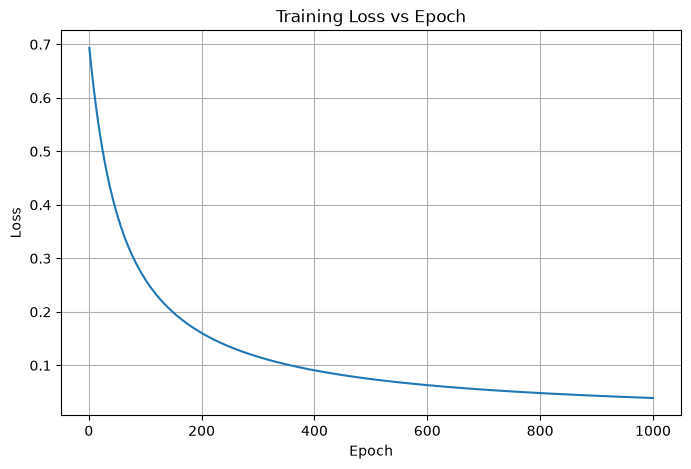

In [90]:
# Encode categorical feature
X_train_encoded, X_test_encoded = encode_categorical(X_train, X_test)

# Calculate scaling values from training data
mean = calculate_mean(X_train_encoded)
std = calculate_std(X_train_encoded, mean)

# Standardize the data
X_train_scaled = standardize(X_train_encoded, mean, std)
X_test_scaled = standardize(X_test_encoded, mean, std)

# Convert to NumPy arrays
X_train_scaled = X_train_scaled.to_numpy(dtype=float)
X_test_scaled = X_test_scaled.to_numpy(dtype=float)


model = LogisticRegression(
    learning_rate=0.01,
    epochs=1000
)

model.fit(X_train_scaled, y_train)

plot_loss_curve(model.loss_history)

## 2. Test Predictions

Now that the model is trained, we use the learned weights and bias to predict the test data.

The model first produces probabilities between 0 and 1.

We then convert those probabilities into class predictions using the 0.5 threshold.

In [92]:
probabilities = predict_probability(
    X_test_scaled,
    model.weights,
    model.bias
)

predictions = probability_to_class(probabilities)

print("First 10 probabilities:")
print(probabilities[:10])

print("\nFirst 10 predictions:")
print(predictions[:10])

First 10 probabilities:
[0.0513711  0.97723205 0.98643692 0.99587765]

First 10 predictions:
[0 1 1 1]


## 3. Model Evaluation

Now we evaluate how well the model performed on unseen test data.

We calculate:

- Accuracy → How many predictions were correct overall?
- Precision → When the model predicts churn, how often is it correct?
- Recall → How many actual churners did the model identify?
- F1 → Balance between precision and recall.

We also visualize the confusion matrix to see the types of correct and incorrect predictions.

Accuracy : 0.25
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


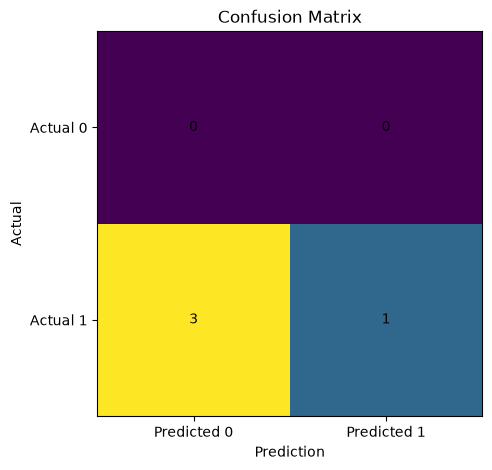

In [93]:
print("Accuracy :", accuracy(y_test, predictions))
print("Precision:", precision(y_test, predictions))
print("Recall   :", recall(y_test, predictions))
print("F1 Score :", f1_score(y_test, predictions))

plot_confusion_matrix(y_test, predictions)

## 4. Learning Rate Experiment

The learning rate controls how large each weight update is during gradient descent.

We will test:

- 0.001 → smaller updates
- 0.01 → baseline
- 0.1 → larger updates

We keep the number of epochs fixed at 1000.

### Question

How does changing the learning rate affect:

- Training loss?
- Accuracy?
- Precision?
- Recall?
- F1 score?

In [97]:
learning_rates = [0.001, 0.01, 0.1]
results = []

for lr in learning_rates:

    model = LogisticRegression(
        learning_rate=lr,
        epochs=1000
    )

    model.fit(X_train_scaled, y_train)

    probabilities = predict_probability(
        X_test_scaled,
        model.weights,
        model.bias
    )

    predictions = probability_to_class(probabilities)

    results.append({
        "learning_rate": lr,
        "loss": model.loss_history[-1],
        "accuracy": accuracy(y_test, predictions),
        "precision": precision(y_test, predictions),
        "recall": recall(y_test, predictions),
        "f1": f1_score(y_test, predictions)
    })

pd.DataFrame(results)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6920829580248538
Epoch 3: Loss = 0.691021385404323
Epoch 4: Loss = 0.6899624558565257
Epoch 5: Loss = 0.6889061625474873
Epoch 6: Loss = 0.6878524986511839
Epoch 7: Loss = 0.6868014573496394
Epoch 8: Loss = 0.6857530318330202
Epoch 9: Loss = 0.6847072152997296
Epoch 10: Loss = 0.6836640009565016
Epoch 11: Loss = 0.6826233820184933
Epoch 12: Loss = 0.6815853517093751
Epoch 13: Loss = 0.6805499032614232
Epoch 14: Loss = 0.6795170299156066
Epoch 15: Loss = 0.6784867249216769
Epoch 16: Loss = 0.6774589815382557
Epoch 17: Loss = 0.6764337930329197
Epoch 18: Loss = 0.6754111526822875
Epoch 19: Loss = 0.6743910537721027
Epoch 20: Loss = 0.6733734895973186
Epoch 21: Loss = 0.6723584534621793
Epoch 22: Loss = 0.671345938680302
Epoch 23: Loss = 0.6703359385747573
Epoch 24: Loss = 0.6693284464781485
Epoch 25: Loss = 0.6683234557326903
Epoch 26: Loss = 0.6673209596902858
Epoch 27: Loss = 0.6663209517126046
Epoch 28: Loss = 0.6653234251711567
Epo

,learning_rate,loss,accuracy,precision,recall,f1
0,0.001,0.260028,0.25,1.0,1.0,1.0
1,0.010,0.038932,0.25,1.0,1.0,1.0
2,0.100,0.004077,0.25,1.0,1.0,1.0


### Learning Rate — Loss Curves

Now we visualize the loss for each learning rate.

We want to see:

- How quickly does the loss decrease?
- Does the loss decrease smoothly?
- Does a large learning rate become unstable?

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6920829580248538
Epoch 3: Loss = 0.691021385404323
Epoch 4: Loss = 0.6899624558565257
Epoch 5: Loss = 0.6889061625474873
Epoch 6: Loss = 0.6878524986511839
Epoch 7: Loss = 0.6868014573496394
Epoch 8: Loss = 0.6857530318330202
Epoch 9: Loss = 0.6847072152997296
Epoch 10: Loss = 0.6836640009565016
Epoch 11: Loss = 0.6826233820184933
Epoch 12: Loss = 0.6815853517093751
Epoch 13: Loss = 0.6805499032614232
Epoch 14: Loss = 0.6795170299156066
Epoch 15: Loss = 0.6784867249216769
Epoch 16: Loss = 0.6774589815382557
Epoch 17: Loss = 0.6764337930329197
Epoch 18: Loss = 0.6754111526822875
Epoch 19: Loss = 0.6743910537721027
Epoch 20: Loss = 0.6733734895973186
Epoch 21: Loss = 0.6723584534621793
Epoch 22: Loss = 0.671345938680302
Epoch 23: Loss = 0.6703359385747573
Epoch 24: Loss = 0.6693284464781485
Epoch 25: Loss = 0.6683234557326903
Epoch 26: Loss = 0.6673209596902858
Epoch 27: Loss = 0.6663209517126046
Epoch 28: Loss = 0.6653234251711567
Epo

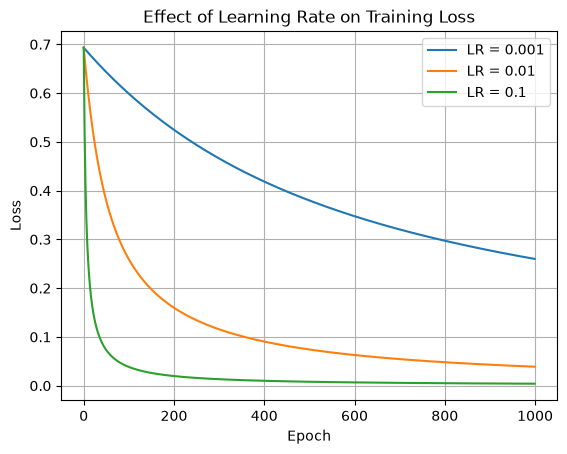

In [99]:
for lr in learning_rates:

    model = LogisticRegression(
        learning_rate=lr,
        epochs=1000
    )

    model.fit(X_train_scaled, y_train)

    plt.plot(
        model.loss_history,
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Learning Rate on Training Loss")
plt.legend()
plt.grid(True)
plt.show()

## 5. Epoch Experiment

An epoch is one complete pass through the training data.

Now we keep the learning rate fixed at 0.01 and change only the number of epochs:

- 100
- 500
- 1000

### Question

Does training for more epochs actually improve the model?

We will compare the final loss and evaluation metrics.

In [100]:
epochs_list = [100, 500, 1000]
epoch_results = []

for epochs in epochs_list:

    model = LogisticRegression(
        learning_rate=0.01,
        epochs=epochs
    )

    model.fit(X_train_scaled, y_train)

    probabilities = predict_probability(
        X_test_scaled,
        model.weights,
        model.bias
    )

    predictions = probability_to_class(probabilities)

    epoch_results.append({
        "epochs": epochs,
        "loss": model.loss_history[-1],
        "accuracy": accuracy(y_test, predictions),
        "precision": precision(y_test, predictions),
        "recall": recall(y_test, predictions),
        "f1": f1_score(y_test, predictions)
    })

pd.DataFrame(epoch_results)

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6825646532181837
Epoch 3: Loss = 0.6722440126705469
Epoch 4: Loss = 0.6621784321875817
Epoch 5: Loss = 0.65236117884003
Epoch 6: Loss = 0.6427856214921512
Epoch 7: Loss = 0.6334452378298108
Epoch 8: Loss = 0.6243336204699597
Epoch 9: Loss = 0.615444482200658
Epoch 10: Loss = 0.6067716604024778
Epoch 11: Loss = 0.5983091207030793
Epoch 12: Loss = 0.5900509599170397
Epoch 13: Loss = 0.5819914083227438
Epoch 14: Loss = 0.5741248313273791
Epoch 15: Loss = 0.5664457305699064
Epoch 16: Loss = 0.5589487445103598
Epoch 17: Loss = 0.5516286485520513
Epoch 18: Loss = 0.5444803547412566
Epoch 19: Loss = 0.5374989110868045
Epoch 20: Loss = 0.5306795005397338
Epoch 21: Loss = 0.5240174396708465
Epoch 22: Loss = 0.5175081770816318
Epoch 23: Loss = 0.5111472915816696
Epoch 24: Loss = 0.5049304901632904
Epoch 25: Loss = 0.4988536058019807
Epoch 26: Loss = 0.49291259510880414
Epoch 27: Loss = 0.4871035358589625
Epoch 28: Loss = 0.481422624418569
Epoc

,epochs,loss,accuracy,precision,recall,f1
0,100,0.260855,0.25,1.0,1.0,1.0
1,500,0.074340,0.25,1.0,1.0,1.0
2,1000,0.038932,0.25,1.0,1.0,1.0


## 6. Epoch Loss Curves

We now visualize how the number of epochs affects training.

We want to observe whether:

- Loss continues decreasing.
- Loss eventually levels off.
- More epochs provide meaningful improvement.

Epoch 1: Loss = 0.6931471805599453
Epoch 2: Loss = 0.6825646532181837
Epoch 3: Loss = 0.6722440126705469
Epoch 4: Loss = 0.6621784321875817
Epoch 5: Loss = 0.65236117884003
Epoch 6: Loss = 0.6427856214921512
Epoch 7: Loss = 0.6334452378298108
Epoch 8: Loss = 0.6243336204699597
Epoch 9: Loss = 0.615444482200658
Epoch 10: Loss = 0.6067716604024778
Epoch 11: Loss = 0.5983091207030793
Epoch 12: Loss = 0.5900509599170397
Epoch 13: Loss = 0.5819914083227438
Epoch 14: Loss = 0.5741248313273791
Epoch 15: Loss = 0.5664457305699064
Epoch 16: Loss = 0.5589487445103598
Epoch 17: Loss = 0.5516286485520513
Epoch 18: Loss = 0.5444803547412566
Epoch 19: Loss = 0.5374989110868045
Epoch 20: Loss = 0.5306795005397338
Epoch 21: Loss = 0.5240174396708465
Epoch 22: Loss = 0.5175081770816318
Epoch 23: Loss = 0.5111472915816696
Epoch 24: Loss = 0.5049304901632904
Epoch 25: Loss = 0.4988536058019807
Epoch 26: Loss = 0.49291259510880414
Epoch 27: Loss = 0.4871035358589625
Epoch 28: Loss = 0.481422624418569
Epoc

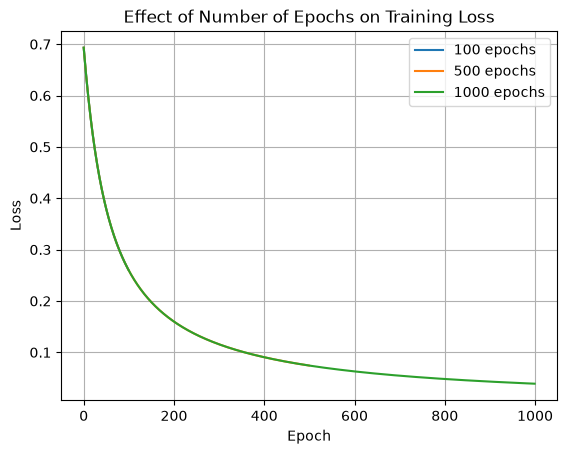

In [101]:
for epochs in epochs_list:

    model = LogisticRegression(
        learning_rate=0.01,
        epochs=epochs
    )

    model.fit(X_train_scaled, y_train)

    plt.plot(
        model.loss_history,
        label=f"{epochs} epochs"
    )

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Effect of Number of Epochs on Training Loss")
plt.legend()
plt.grid(True)
plt.show()

## 7. Final Analysis

After running the experiments, answer these questions based on our actual results:

### Learning Rate
- Which learning rate trained fastest?
- Which learning rate gave the lowest final loss?
- Did the largest learning rate remain stable?

### Epochs
- Did increasing the number of epochs reduce the loss?
- Did more epochs improve the test metrics?
- Did the improvement become smaller after a certain number of epochs?

### Model Evaluation
- What were the Accuracy, Precision, Recall, and F1 scores?
- Is accuracy alone enough to judge this churn model?
- Which metric is particularly important for detecting customers who may churn?

### Conclusion
Based on the experiments, which learning rate and number of epochs would you choose, and why?